# 13 温度優先・湿度優先・再熱

顕熱需要がほぼなく湿度が高い条件で、3つの制御方針を比較する。

## 到達目標
温度優先はRH未達を許す。湿度優先は過冷却上限内で除湿。温湿度満足は再熱を用いる。室RHと吹出RHを混同しない。

## 実行環境
Python 3.10以上とvtsimnx engineが必要です。Colabのlocalhostは手元PCのサーバーを指しません。次の設定セルのAPI URLを到達可能なものに変更します。APIキーは環境変数で渡し、ノートに保存しません。

検証engine commit: `5eeffb2f8012a2fe41bca705450b0dd0a952326d`。入力モデルは実計算確認済ですが、原住宅の年間再現とは範囲が異なります。

## 実行版の使い方
このノートは検証対象のvtsimnx commit 5eeffb2f8012a2fe41bca705450b0dd0a952326d に合わせた代表教材です。上から順に実行します。
Pythonクライアントの導入だけではengineは起動しません。教材17以外は接続可能なengineと、必要に応じてVTSIMNX_API_KEYが必要です。Colabの127.0.0.1は手元PCのengineを指しません。
入力はノート内に含めています。元のDriveパスや測定CSVを別途読む必要はありません。
出力は教材フォルダ内のresults/13/に保存します。詳しい準備は同じフォルダの00_実行ガイド.ipynbを参照してください。


In [1]:
import os, sys, subprocess
# 検証runnerのみ専用環境で導入済みの依存を再利用する。通常はこのセルで導入する。
if os.environ.get("VTSIMNX_TUTORIAL_SKIP_INSTALL") != "1":
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", "pip", "setuptools>=68,<81", "wheel"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
        "vtsimnx @ git+https://github.com/iguchi-lab/vtsimnx@5eeffb2f8012a2fe41bca705450b0dd0a952326d",
        "matplotlib", "japanize-matplotlib"])


In [2]:
import os, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import japanize_matplotlib
from IPython.display import display
import vtsimnx as vt

# ローカルJupyterでは、ノートブックと同じフォルダを作業フォルダにする。
DATA_DIR = Path(os.environ.get("VTSIMNX_TUTORIAL_DATA", ".")).expanduser().resolve()
BASE_URL = os.environ.get("VTSIMNX_API_URL", "http://127.0.0.1:8000")
API_KEY = os.environ.get("VTSIMNX_API_KEY")
OUTPUT = DATA_DIR / "results" / "13"
OUTPUT.mkdir(parents=True, exist_ok=True)


## 入力を読む
次の辞書はvtsimnxのネイティブ形式です。風量はm³/s、熱量はW、熱容量はJ/Kです。

In [3]:
configs = {'13_temperature_priority': {'builder': {},
                             'simulation': {'index': {'start': '2026-01-01T00:00:00',
                                                      'end': '2026-01-01T05:00:00',
                                                      'length': 6,
                                                      'timestep': 3600},
                                            'coupling': {'moisture_enabled': True},
                                            'tolerance': {'thermal': 0.001,
                                                          'convergence': 1e-06,
                                                          'coupling_humidity': 1e-08}},
                             'nodes': [{'key': 'outside', 't': 26, 'x': 0.018},
                                       {'key': 'room',
                                        't': 26,
                                        'x': 0.018,
                                        'v': 40,
                                        'calc_t': True,
                                        'calc_x': True}],
                             'ventilation_branches': [{'key': 'outside->room',
                                                       'source': 'outside',
                                                       'target': 'room',
                                                       'vol': 0.05},
                                                      {'key': 'room->outside',
                                                       'source': 'room',
                                                       'target': 'outside',
                                                       'vol': 0.05}],
                             'thermal_branches': [{'key': 'outside->room',
                                                   'source': 'outside',
                                                   'target': 'room',
                                                   'conductance': 1000}],
                             'aircon': [{'key': 'AC',
                                         'set': 'room',
                                         'outside': 'outside',
                                         'pre_temp': 26,
                                         'pre_rh': 60,
                                         'mode': 'COOLING',
                                         'model': 'RAC',
                                         'vol': 0.1,
                                         'control_mode': 'temperature_priority',
                                         'max_overcooling': 2,
                                         'ac_spec': {'latent_method': 'rh100',
                                                     'bf': 0.2,
                                                     'Af': 0.133,
                                                     'Ao': 4.84,
                                                     'Q': {'cooling': {'min': 0.01,
                                                                       'mid': 3.8,
                                                                       'rtd': 7.6,
                                                                       'max': 20},
                                                           'heating': {'min': 2.7, 'mid': 3.9, 'rtd': 7.7}},
                                                     'P': {'cooling': {'rtd': 2.4},
                                                           'heating': {'rtd': 2.1}}}}]},
 '13_humidity_priority': {'builder': {},
                          'simulation': {'index': {'start': '2026-01-01T00:00:00',
                                                   'end': '2026-01-01T05:00:00',
                                                   'length': 6,
                                                   'timestep': 3600},
                                         'coupling': {'moisture_enabled': True},
                                         'tolerance': {'thermal': 0.001,
                                                       'convergence': 1e-06,
                                                       'coupling_humidity': 1e-08}},
                          'nodes': [{'key': 'outside', 't': 26, 'x': 0.018},
                                    {'key': 'room',
                                     't': 26,
                                     'x': 0.018,
                                     'v': 40,
                                     'calc_t': True,
                                     'calc_x': True}],
                          'ventilation_branches': [{'key': 'outside->room',
                                                    'source': 'outside',
                                                    'target': 'room',
                                                    'vol': 0.05},
                                                   {'key': 'room->outside',
                                                    'source': 'room',
                                                    'target': 'outside',
                                                    'vol': 0.05}],
                          'thermal_branches': [{'key': 'outside->room',
                                                'source': 'outside',
                                                'target': 'room',
                                                'conductance': 1000}],
                          'aircon': [{'key': 'AC',
                                      'set': 'room',
                                      'outside': 'outside',
                                      'pre_temp': 26,
                                      'pre_rh': 60,
                                      'mode': 'COOLING',
                                      'model': 'RAC',
                                      'vol': 0.1,
                                      'control_mode': 'humidity_priority',
                                      'max_overcooling': 2,
                                      'ac_spec': {'latent_method': 'ideal_coil',
                                                  'bf': 0.2,
                                                  'Af': 0.133,
                                                  'Ao': 4.84,
                                                  'Q': {'cooling': {'min': 0.01,
                                                                    'mid': 3.8,
                                                                    'rtd': 7.6,
                                                                    'max': 20},
                                                        'heating': {'min': 2.7, 'mid': 3.9, 'rtd': 7.7}},
                                                  'P': {'cooling': {'rtd': 2.4}, 'heating': {'rtd': 2.1}}}}]},
 '13_temperature_humidity': {'builder': {},
                             'simulation': {'index': {'start': '2026-01-01T00:00:00',
                                                      'end': '2026-01-01T05:00:00',
                                                      'length': 6,
                                                      'timestep': 3600},
                                            'coupling': {'moisture_enabled': True},
                                            'tolerance': {'thermal': 0.001,
                                                          'convergence': 1e-06,
                                                          'coupling_humidity': 1e-08}},
                             'nodes': [{'key': 'outside', 't': 26, 'x': 0.018},
                                       {'key': 'room',
                                        't': 26,
                                        'x': 0.018,
                                        'v': 40,
                                        'calc_t': True,
                                        'calc_x': True}],
                             'ventilation_branches': [{'key': 'outside->room',
                                                       'source': 'outside',
                                                       'target': 'room',
                                                       'vol': 0.05},
                                                      {'key': 'room->outside',
                                                       'source': 'room',
                                                       'target': 'outside',
                                                       'vol': 0.05}],
                             'thermal_branches': [{'key': 'outside->room',
                                                   'source': 'outside',
                                                   'target': 'room',
                                                   'conductance': 1000}],
                             'aircon': [{'key': 'AC',
                                         'set': 'room',
                                         'outside': 'outside',
                                         'pre_temp': 26,
                                         'pre_rh': 60,
                                         'mode': 'COOLING',
                                         'model': 'RAC',
                                         'vol': 0.1,
                                         'control_mode': 'temperature_humidity',
                                         'max_overcooling': 2,
                                         'ac_spec': {'latent_method': 'ideal_coil',
                                                     'bf': 0.2,
                                                     'Af': 0.133,
                                                     'Ao': 4.84,
                                                     'Q': {'cooling': {'min': 0.01,
                                                                       'mid': 3.8,
                                                                       'rtd': 7.6,
                                                                       'max': 20},
                                                           'heating': {'min': 2.7, 'mid': 3.9, 'rtd': 7.7}},
                                                     'P': {'cooling': {'rtd': 2.4},
                                                           'heating': {'rtd': 2.1}}}}]}}


## 実行と結果の取得
計算ごとの要求JSONを保存し、必要な系列をDataFrameとして取得します。

In [4]:
results = {}
for name, config in configs.items():
    results[name] = vt.run_calc(BASE_URL, config, api_key=API_KEY,
        as_result=True, raise_on_error=True, timeout=1800, request_output_path=OUTPUT / (name + "_request.json"))
    print(name, results[name].artifact_dir)


13_temperature_priority artifacts.1794699423407.output.728ec74958a2476087945091973ee108


13_humidity_priority artifacts.1794699424422.output.f45d70d4c10e4901b53a08d3d0b3cb44


13_temperature_humidity artifacts.1794699425440.output.17ac40dbf0614008876a75066568b59d


13_temperature_priority


,AC,outside,room
time,,,
2026-01-01 00:00:00,26.0,26.0,26.0
2026-01-01 01:00:00,26.0,26.0,26.0
2026-01-01 02:00:00,26.0,26.0,26.0
2026-01-01 03:00:00,26.0,26.0,26.0
2026-01-01 04:00:00,26.0,26.0,26.0


13_humidity_priority


,AC,outside,room
time,,,
2026-01-01 00:00:00,9.491058,26.0,24.312595
2026-01-01 01:00:00,11.261803,26.0,24.493586
2026-01-01 02:00:00,11.229988,26.0,24.490334
2026-01-01 03:00:00,11.230563,26.0,24.490393
2026-01-01 04:00:00,11.230553,26.0,24.490393


13_temperature_humidity


,AC,outside,room
time,,,
2026-01-01 00:00:00,26.0,26.0,26.0
2026-01-01 01:00:00,26.0,26.0,26.0
2026-01-01 02:00:00,26.0,26.0,26.0
2026-01-01 03:00:00,26.0,26.0,26.0
2026-01-01 04:00:00,26.0,26.0,26.0


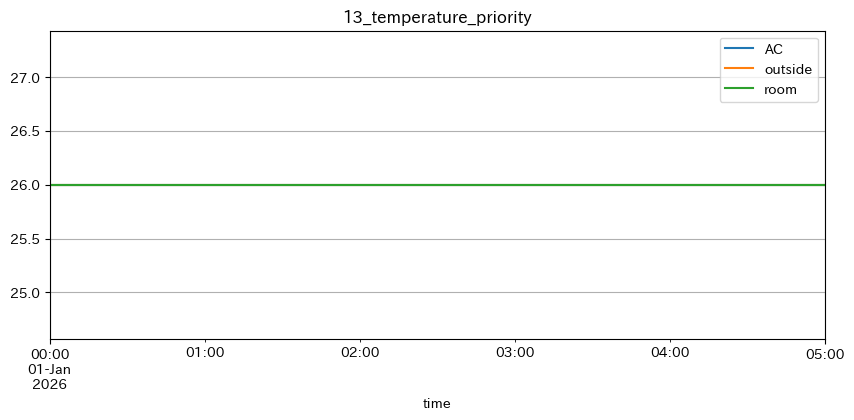

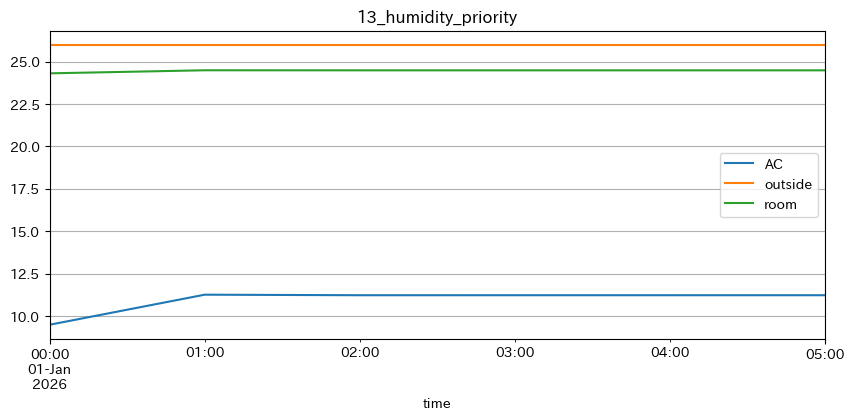

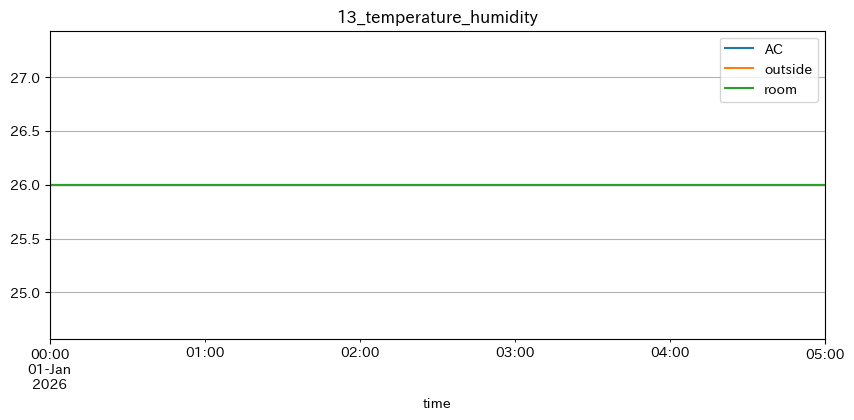

In [5]:
frames = {name: result.get_series_df('thermal_temperature', raise_on_error=True) for name, result in results.items()}
for name, frame in frames.items():
    print(name)
    display(frame.head())
    frame.to_csv(OUTPUT / (name + "_thermal_temperature.csv"), encoding="utf-8-sig")
    frame.plot(title=name, figsize=(10, 4), grid=True)


In [6]:
for name, result in results.items():
    for key in ["aircon_room_rh", "aircon_reheat", "aircon_humidity_unmet", "aircon_power"]:
        print(name, key)
        display(result.get_series_df(key, raise_on_error=True).tail(1))


13_temperature_priority aircon_room_rh


,AC
time,
2026-01-01 05:00:00,84.80307


13_temperature_priority aircon_reheat


,AC
time,
2026-01-01 05:00:00,0.0


13_temperature_priority aircon_humidity_unmet


,AC
time,
2026-01-01 05:00:00,24.803068


... (14 outputs left out)

13_temperature_humidity aircon_humidity_unmet


,AC
time,
2026-01-01 05:00:00,0.0


13_temperature_humidity aircon_power


,AC
time,
2026-01-01 05:00:00,1997.808105


## 確認・発展
最大過冷却を0.2Kに制限し、humidity_unmetを確認する。

保存された時刻の値は当該ステップ更新後の値です。初期値との比較ではこの差に注意します。

## 原典との対応
- S001 250929_再熱考慮_電中研モデル.ipynb
- S036 電中研モデル_250210.ipynb のコピー
- S037 電中研モデル_再熱考慮_旧エアコン250727.ipynb
- S182 240310_集合住宅向け床吹出型全館空調_モデル化_K_1.ipynb
- S183 240310_集合住宅向け床吹出型全館空調_モデル化_K_2.ipynb
- S184 240310_集合住宅向け床吹出型全館空調_モデル化_K_3.ipynb
- S185 240310_集合住宅向け床吹出型全館空調_モデル化_K_4.ipynb
- S186 240310_集合住宅向け床吹出型全館空調_モデル化_K_5.ipynb
- S187 240310_集合住宅向け床吹出型全館空調_モデル化_M-1.ipynb
- S188 240310_集合住宅向け床吹出型全館空調_モデル化_M-2.ipynb
- S189 240310_集合住宅向け床吹出型全館空調_モデル化_SC.ipynb
- S261 Duct_Central_ACモデル.ipynb のコピー

S番号は原典調査時の識別子です。原典の完全な台帳は管理者のDrive整理資料に保管しています。